# Implemntereting af single layer perceptron

## 1. Import af bibliotek

Matplotlib bruges til at visualisere træningsdataene og modellens beslutningsgrænse.

In [45]:
import matplotlib.pyplot as plt

## 2. Oprettelse af Perceptron-klassen

Klassen indeholder modellens vægte, bias og læringsrate. Den indeholder også metoder til aktivering, forudsigelse og træning.

In [46]:
# Opret Perceptron som en klasse der har værdierne vægt, bias og læringsrate

class Perceptron:
    def __init__(self, antal_inputs):
        # Der skal være en vægt for hvert input.
        # Nulstart gør modellen neutral, før den er blevet trænet.
        self.vægt = [0] * antal_inputs
        # Bias flytter beslutningsgrænsen uafhængigt af inputværdierne.
        self.bias = 0
        # En lille læringsrate giver mindre vægtjusteringer ad gangen.
        self.læringsrate = 0.001


    def aktiveringsfunktion(self, værdi):
        # aktiveringsfunktionen omdanner den vægtede sum til en klasse: 0 eller 1.
        if værdi >= 0:
            return 1
        else:
            return 0


    def forudsig(self, inputs):
        # Start med bias, og læg hvert input ganget med sin vægt til.
        samlet_værdi = self.bias

        for i in range(len(inputs)):
            samlet_værdi += inputs[i] * self.vægt[i]
        return self.aktiveringsfunktion(samlet_værdi)


    def træn(self, træningsdata, antal_epoker):
        # En epoke betyder, at modellen gennemgår hele datasættet én gang.
        for epoke in range(antal_epoker):
            for inputs, forventet in træningsdata:
                forudsigelse = self.forudsig(inputs)
                # Fejlen viser, om forudsigelsen skal op eller ned.
                fejl = forventet - forudsigelse

                # Vægtene justeres i retning af det korrekte svar.
                # Inputtet bestemmer, hvilke vægte der påvirkes.
                for i in range(len(self.vægt)):
                    self.vægt[i] += self.læringsrate * fejl * inputs[i]
                # Bias justeres også, så beslutningsgrænsen kan flyttes.
                self.bias += self.læringsrate * fejl

## 3. OR-træningsdata

Hvert eksempel består af inputværdierne og det korrekte svar. OR-logik giver 1, hvis mindst ét af de to input er 1.

In [47]:
# Hvert eksempel er (inputværdier, korrekt svar).
# OR giver 1, hvis mindst ét af de to input er 1.
træningsdata = [
    ([0, 0], 0),
    ([0, 1], 1),
    ([1, 0], 1),
    ([1, 1], 1),
]

## 4. Træning af modellen

Her oprettes en perceptron med to input. Modellen trænes derefter på OR-datasættet i 1000 epoker.

In [48]:
perceptron = Perceptron(2)
perceptron.træn(træningsdata, 20)

## 5. Modellens forudsigelser

Sammenlignes modellens forudsigelse sammenlignes med det korrekte svar for hvert eksempel i træningsdataene.

In [49]:
# Sammenlign modellens forudsigelse med det korrekte svar.
for inputs, forventet in træningsdata:
    print(inputs, "->", perceptron.forudsig(inputs), "(forventet:", forventet, ")")

[0, 0] -> 0 (forventet: 0 )
[0, 1] -> 1 (forventet: 1 )
[1, 0] -> 1 (forventet: 1 )
[1, 1] -> 1 (forventet: 1 )


## 6. Visualisering af træningsdata og beslutningsgrænse

Datapunkterne vises med forskellige farver alt efter deres klasse. Den røde linje viser perceptronens beslutningsgrænse.

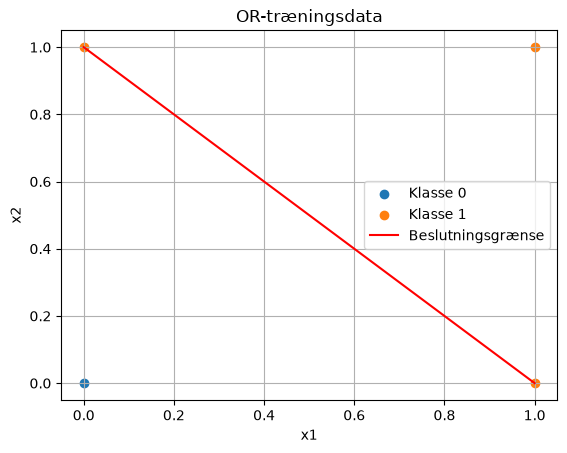

In [50]:
# Tegn datapunkterne med hver sin farve, så klasserne kan skelnes.
for klasse, farve, navn in [
    (0, "tab:blue", "Klasse 0"),
    (1, "tab:orange", "Klasse 1"),
]:
    punkter = [
        inputs for inputs, svar in træningsdata
        if svar == klasse
    ]
    plt.scatter(
        [punkt[0] for punkt in punkter],
        [punkt[1] for punkt in punkter],
        color=farve,
        label=navn,
    )

# Grænsen ligger, hvor vægt * input + bias = 0.
# Løs ligningen for x2 ved to x1-værdier for at tegne linjen.
x1_værdier = [0, 1]
x2_værdier = [
    (-perceptron.bias - perceptron.vægt[0] * x1) / perceptron.vægt[1]
    for x1 in x1_værdier
]
plt.plot(x1_værdier, x2_værdier, color="red", label="Beslutningsgrænse")


plt.xlabel("x1")
plt.ylabel("x2")
plt.title("OR-træningsdata")
plt.legend()
plt.grid(True)
# Vis grafen i et separat vindue.
plt.show()